In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils import check_random_state
import joblib

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
# Works when notebook is run from the project root or from the notebooks folder.
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "CIA3_Phase2_Final_Labelled_Dataset.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)


Project root: C:\Users\Prit Sachani\Pictures\NLP_Projext\CIA3_Phase2_Model_Development
Dataset path: C:\Users\Prit Sachani\Pictures\NLP_Projext\CIA3_Phase2_Model_Development\data\CIA3_Phase2_Final_Labelled_Dataset.csv


In [2]:
df = pd.read_csv(DATA_PATH)

required_columns = ["classification_text", "final_model_label", "include_in_initial_training"]
missing = [col for col in required_columns if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Keep only records approved as initial training candidates.
df["include_in_initial_training"] = (
    df["include_in_initial_training"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
)
model_df = df.loc[df["include_in_initial_training"]].copy()
model_df["classification_text"] = model_df["classification_text"].fillna("").astype(str).str.strip()
model_df["final_model_label"] = model_df["final_model_label"].fillna("").astype(str).str.strip()
model_df = model_df[
    model_df["classification_text"].ne("") & model_df["final_model_label"].ne("")
].reset_index(drop=True)

print("Original records:", len(df))
print("Training candidates after filtering:", len(model_df))
print("Excluded records:", len(df) - len(model_df))
print("\nClass distribution:")
display(model_df["final_model_label"].value_counts().to_frame("notice_count"))


Original records: 455
Training candidates after filtering: 447
Excluded records: 8

Class distribution:


,notice_count
final_model_label,
Infrastructure & Maintenance Works,328
"Campus, Academic & Administrative Services",65
Goods & Equipment Procurement,54


In [3]:
X = model_df["classification_text"]
y = model_df["final_model_label"]

class_counts = y.value_counts()
if class_counts.min() < 2:
    raise ValueError("At least two examples per class are required for a stratified train/test split.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nTraining distribution:")
display(y_train.value_counts().to_frame("train_count"))
print("\nTesting distribution:")
display(y_test.value_counts().to_frame("test_count"))


Training records: 357
Testing records: 90

Training distribution:


,train_count
final_model_label,
Infrastructure & Maintenance Works,262
"Campus, Academic & Administrative Services",52
Goods & Equipment Procurement,43



Testing distribution:


,test_count
final_model_label,
Infrastructure & Maintenance Works,66
"Campus, Academic & Administrative Services",13
Goods & Equipment Procurement,11


In [4]:
def make_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=15000,
        sublinear_tf=True
    )

# Show feature dimensions after fitting on training text only.
preview_vectorizer = make_tfidf()
X_train_tfidf = preview_vectorizer.fit_transform(X_train)
X_test_tfidf = preview_vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(preview_vectorizer.vocabulary_))


Training TF-IDF shape: (357, 15000)
Testing TF-IDF shape: (90, 15000)
Vocabulary size: 15000


In [5]:
nb_pipeline = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", MultinomialNB(alpha=1.0))
])
nb_pipeline.fit(X_train, y_train)
nb_predictions = nb_pipeline.predict(X_test)

print("Multinomial Naive Bayes – Classification Report")
print(classification_report(y_test, nb_predictions, zero_division=0))


Multinomial Naive Bayes – Classification Report
                                            precision    recall  f1-score   support

Campus, Academic & Administrative Services       1.00      0.23      0.38        13
             Goods & Equipment Procurement       0.71      0.45      0.56        11
        Infrastructure & Maintenance Works       0.80      0.97      0.88        66

                                  accuracy                           0.80        90
                                 macro avg       0.84      0.55      0.60        90
                              weighted avg       0.82      0.80      0.76        90



In [6]:
svm_pipeline = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", LinearSVC(C=1.0, class_weight=None, random_state=RANDOM_STATE))
])
svm_pipeline.fit(X_train, y_train)
svm_predictions = svm_pipeline.predict(X_test)

print("Linear SVM – Classification Report")
print(classification_report(y_test, svm_predictions, zero_division=0))


Linear SVM – Classification Report
                                            precision    recall  f1-score   support

Campus, Academic & Administrative Services       1.00      0.85      0.92        13
             Goods & Equipment Procurement       0.86      0.55      0.67        11
        Infrastructure & Maintenance Works       0.90      0.98      0.94        66

                                  accuracy                           0.91        90
                                 macro avg       0.92      0.79      0.84        90
                              weighted avg       0.91      0.91      0.90        90



In [7]:
def calculate_metrics(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

baseline_results = pd.DataFrame([
    calculate_metrics("Multinomial Naive Bayes", y_test, nb_predictions),
    calculate_metrics("Linear SVM", y_test, svm_predictions)
])
display(baseline_results.round(4))
baseline_results.to_csv(OUTPUT_DIR / "baseline_model_comparison.csv", index=False)


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),F1-score (weighted)
0,Multinomial Naive Bayes,0.8000,0.8381,0.5517,0.6024,0.7650
1,Linear SVM,0.9111,0.9200,0.7922,0.8418,0.9047


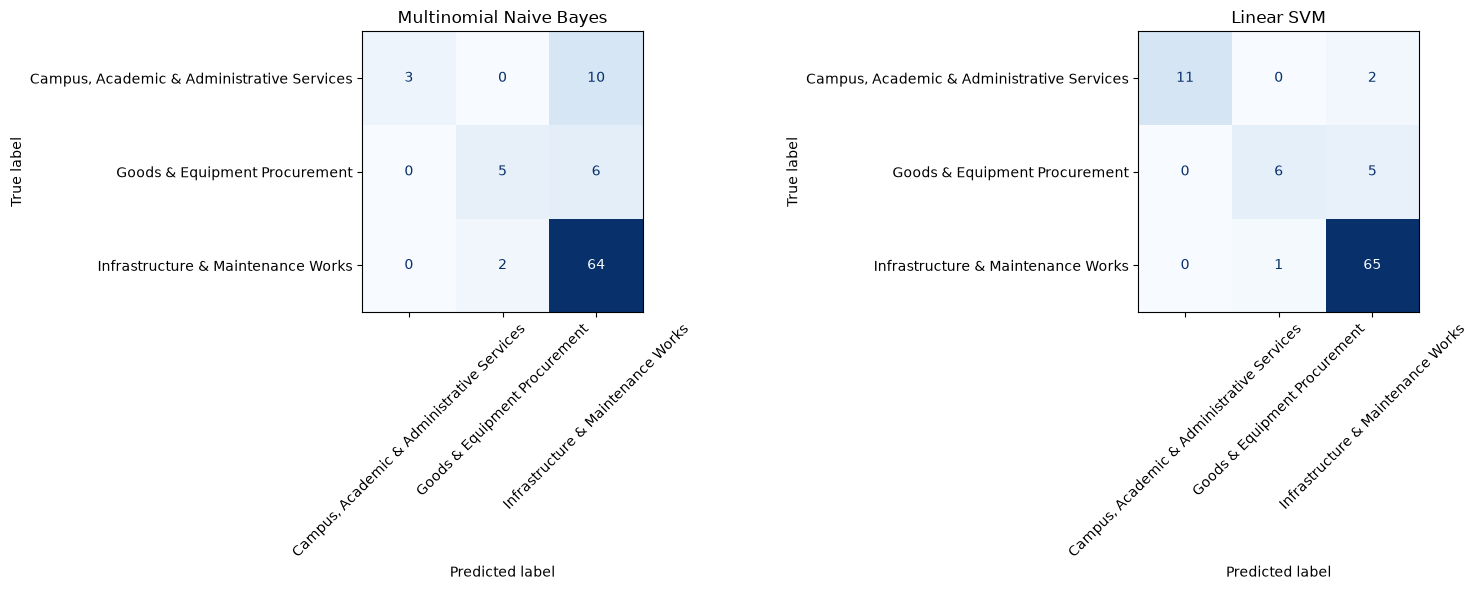

In [8]:
labels = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, name, pred in [
    (axes[0], "Multinomial Naive Bayes", nb_predictions),
    (axes[1], "Linear SVM", svm_predictions)
]:
    cm = confusion_matrix(y_test, pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baseline_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:
error_analysis = model_df.loc[X_test.index, ["notice_id", "title_from_archive", "classification_text", "final_model_label"]].copy()
error_analysis["naive_bayes_prediction"] = nb_predictions
error_analysis["svm_prediction"] = svm_predictions
error_analysis["nb_correct"] = error_analysis["naive_bayes_prediction"] == error_analysis["final_model_label"]
error_analysis["svm_correct"] = error_analysis["svm_prediction"] == error_analysis["final_model_label"]
errors = error_analysis.loc[~(error_analysis["nb_correct"] & error_analysis["svm_correct"])].copy()

print("Test records with at least one model error:", len(errors))
display(errors[[
    "notice_id", "title_from_archive", "final_model_label",
    "naive_bayes_prediction", "svm_prediction",
    "nb_correct", "svm_correct"
]].head(30))
errors.to_csv(OUTPUT_DIR / "error_analysis.csv", index=False)


Test records with at least one model error: 21


,notice_id,title_from_archive,final_model_label,naive_bayes_prediction,svm_prediction,nb_correct,svm_correct
68,a1ff95da2322,Cleaning of Over Head Water Tanks at North A &...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works,"Campus, Academic & Administrative Services",False,True
27,48087f688754,Name of work:- “Providing and fixing 36W LED l...,Goods & Equipment Procurement,Infrastructure & Maintenance Works,Infrastructure & Maintenance Works,False,False
410,8c05a2459e56,Cleaning of Over Head Water Tanks at Men's Hos...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works,"Campus, Academic & Administrative Services",False,True
31,20ac7e6f530b,Cleaning of Over Head Water Tanks at Men's & L...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works,"Campus, Academic & Administrative Services",False,True
302,a5aab2aba32a,"Supply, Installation, Testing and Commissionin...",Goods & Equipment Procurement,Goods & Equipment Procurement,Infrastructure & Maintenance Works,True,False
275,48b9c4cb72fa,Maintenance of Buildings: Cleaning of jungle f...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works,"Campus, Academic & Administrative Services",False,True
34,10e94fc3953d,Cleaning of Over Head Water Tanks at Ladies Ho...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works,"Campus, Academic & Administrative Services",False,True
248,322ccedd46b8,Maintenance of buildings: Supply of Drainage C...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works,"Campus, Academic & Administrative Services",False,True
66,a765f0868306,Replacement of Sealed Maintenance Free (SMF) B...,Infrastructure & Maintenance Works,Infrastructure & Maintenance Works,Goods & Equipment Procurement,True,False
407,836dd14258ba,Cleaning of Over Head Water Tanks at Earth sci...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works,"Campus, Academic & Administrative Services",False,True


In [11]:
tuned_pipeline = Pipeline([
    ("tfidf", make_tfidf()),
    ("classifier", LinearSVC(random_state=RANDOM_STATE))
])

min_train_class = int(y_train.value_counts().min())
cv_splits = min(5, min_train_class)
if cv_splits < 2:
    raise ValueError("Not enough examples in the smallest training class for cross-validation.")

cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
param_grid = {
    "classifier__C": [0.1, 0.5, 1.0, 2.0, 5.0],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=tuned_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro F1:", round(grid_search.best_score_, 4))

tuned_svm = grid_search.best_estimator_
tuned_predictions = tuned_svm.predict(X_test)
print("\nTuned Linear SVM – Held-out Test Report")
print(classification_report(y_test, tuned_predictions, zero_division=0))


Best parameters: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced'}
Best cross-validation macro F1: 0.8742

Tuned Linear SVM – Held-out Test Report
                                            precision    recall  f1-score   support

Campus, Academic & Administrative Services       1.00      0.85      0.92        13
             Goods & Equipment Procurement       0.78      0.64      0.70        11
        Infrastructure & Maintenance Works       0.91      0.97      0.94        66

                                  accuracy                           0.91        90
                                 macro avg       0.90      0.82      0.85        90
                              weighted avg       0.91      0.91      0.91        90



In [12]:
final_results = pd.DataFrame([
    calculate_metrics("Multinomial Naive Bayes", y_test, nb_predictions),
    calculate_metrics("Linear SVM (baseline)", y_test, svm_predictions),
    calculate_metrics("Linear SVM (tuned)", y_test, tuned_predictions)
])
display(final_results.round(4))
final_results.to_csv(OUTPUT_DIR / "final_model_comparison.csv", index=False)

best_model_name = final_results.sort_values("F1-score (macro)", ascending=False).iloc[0]["Model"]
print("Best model by held-out macro F1:", best_model_name)


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),F1-score (weighted)
0,Multinomial Naive Bayes,0.8000,0.8381,0.5517,0.6024,0.7650
1,Linear SVM (baseline),0.9111,0.9200,0.7922,0.8418,0.9047
2,Linear SVM (tuned),0.9111,0.8974,0.8174,0.8526,0.9082


Best model by held-out macro F1: Linear SVM (tuned)


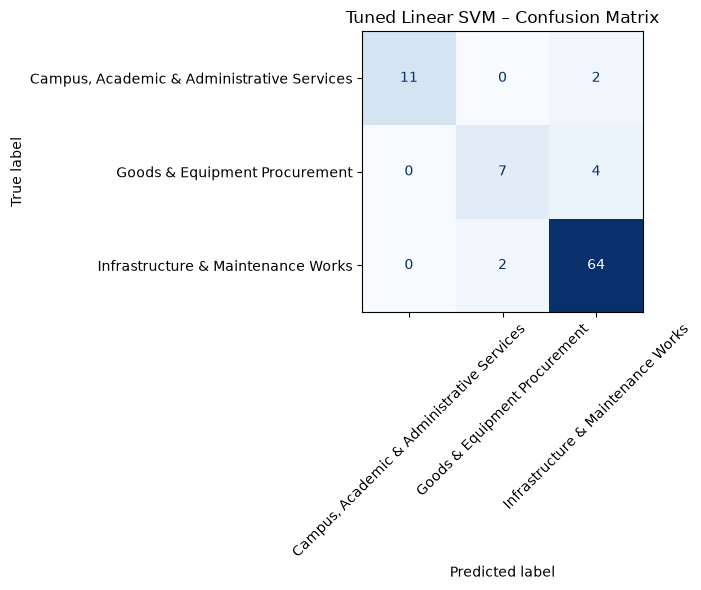

,notice_id,title_from_archive,final_model_label,predicted_label
27,48087f688754,Name of work:- “Providing and fixing 36W LED l...,Goods & Equipment Procurement,Infrastructure & Maintenance Works
66,a765f0868306,Replacement of Sealed Maintenance Free (SMF) B...,Infrastructure & Maintenance Works,Goods & Equipment Procurement
387,d6640dea060a,Supply and fixing of loop pressure sensor and ...,Goods & Equipment Procurement,Infrastructure & Maintenance Works
102,1b0159bb9fda,Maintenance of Buildings’’ Providing and fixin...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works
301,d28fb24e951c,Maintenance of Buildings:- Replacement of 50KW...,Infrastructure & Maintenance Works,Goods & Equipment Procurement
93,74534b7a8a7a,Supply and fixing of Stainless (SS) tank and 2...,"Campus, Academic & Administrative Services",Infrastructure & Maintenance Works
126,7e0b6d6650ba,"Supply, Installation, Testing and Commissionin...",Goods & Equipment Procurement,Infrastructure & Maintenance Works
337,9b79eb3c2463,Maintenance of buildings: Filling up the cavit...,Goods & Equipment Procurement,Infrastructure & Maintenance Works


In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, tuned_predictions, labels=labels)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues"
)
ax.set_title("Tuned Linear SVM – Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tuned_svm_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

tuned_errors = model_df.loc[X_test.index, ["notice_id", "title_from_archive", "classification_text", "final_model_label"]].copy()
tuned_errors["predicted_label"] = tuned_predictions
tuned_errors["correct"] = tuned_errors["final_model_label"] == tuned_errors["predicted_label"]
tuned_errors = tuned_errors.loc[~tuned_errors["correct"]]
display(tuned_errors[["notice_id", "title_from_archive", "final_model_label", "predicted_label"]].head(30))
tuned_errors.to_csv(OUTPUT_DIR / "tuned_svm_error_analysis.csv", index=False)


In [14]:
joblib.dump(nb_pipeline, MODEL_DIR / "naive_bayes_pipeline.joblib")
joblib.dump(svm_pipeline, MODEL_DIR / "linear_svm_baseline_pipeline.joblib")
joblib.dump(tuned_svm, MODEL_DIR / "linear_svm_tuned_pipeline.joblib")

print("Saved models to:", MODEL_DIR)


Saved models to: C:\Users\Prit Sachani\Pictures\NLP_Projext\CIA3_Phase2_Model_Development\models


In [15]:
# Replace these examples with fresh notices not present in the training/test dataset.
new_notices = [
    "Quotation for replacement of damaged electrical cables and installation of LED lights in university buildings.",
    "Supply and installation of laboratory scientific equipment for the Department of Physics.",
    "Cleaning of overhead water tanks in the university hostel buildings."
]

demo_predictions = tuned_svm.predict(new_notices)
demo_output = pd.DataFrame({
    "new_notice_text": new_notices,
    "predicted_category": demo_predictions
})
display(demo_output)


,new_notice_text,predicted_category
0,Quotation for replacement of damaged electrica...,Goods & Equipment Procurement
1,Supply and installation of laboratory scientif...,Goods & Equipment Procurement
2,Cleaning of overhead water tanks in the univer...,"Campus, Academic & Administrative Services"
